## 📈 Marketing Sales Prediction

Given *data about budgets in a marketing campaign*, let's try to predict the **sales** generated by a given budget allocation.

We will use a gradient boosting regression model to make our predictions.

Data source: https://www.kaggle.com/datasets/harrimansaragih/dummy-advertising-and-sales-data

### Importing Libraries

In [2]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns
sns.set_style('darkgrid')

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.ensemble import GradientBoostingRegressor

In [3]:
data = pd.read_csv('archive/Dummy Data HSS.csv')
data

,TV,Radio,Social Media,Influencer,Sales
0,16.0,6.566231,2.907983,Mega,54.732757
1,13.0,9.237765,2.409567,Mega,46.677897
2,41.0,15.886446,2.913410,Mega,150.177829
3,83.0,30.020028,6.922304,Mega,298.246340
4,15.0,8.437408,1.405998,Micro,56.594181
...,...,...,...,...,...
4567,26.0,4.472360,0.717090,Micro,94.685866
4568,71.0,20.610685,6.545573,Nano,249.101915
4569,44.0,19.800072,5.096192,Micro,163.631457
4570,71.0,17.534640,1.940873,Macro,253.610411


In [4]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4572 entries, 0 to 4571
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   TV            4562 non-null   float64
 1   Radio         4568 non-null   float64
 2   Social Media  4566 non-null   float64
 3   Influencer    4572 non-null   object 
 4   Sales         4566 non-null   float64
dtypes: float64(4), object(1)
memory usage: 178.7+ KB


### Preprocessing

In [5]:
df = data.copy()

In [6]:
df

,TV,Radio,Social Media,Influencer,Sales
0,16.0,6.566231,2.907983,Mega,54.732757
1,13.0,9.237765,2.409567,Mega,46.677897
2,41.0,15.886446,2.913410,Mega,150.177829
3,83.0,30.020028,6.922304,Mega,298.246340
4,15.0,8.437408,1.405998,Micro,56.594181
...,...,...,...,...,...
4567,26.0,4.472360,0.717090,Micro,94.685866
4568,71.0,20.610685,6.545573,Nano,249.101915
4569,44.0,19.800072,5.096192,Micro,163.631457
4570,71.0,17.534640,1.940873,Macro,253.610411


In [8]:
# Missing values
df.isna().sum()

TV              10
Radio            4
Social Media     6
Influencer       0
Sales            6
dtype: int64

In [9]:
# Drop rows with missing target values
df['Sales'].isna()

0       False
1       False
2       False
3       False
4       False
        ...  
4567    False
4568    False
4569    False
4570    False
4571    False
Name: Sales, Length: 4572, dtype: bool

In [12]:
missing_target_rows = df[df['Sales'].isna()].index

df = df.drop(missing_target_rows, axis=0).reset_index(drop=True)

In [13]:
df.isna().sum()

TV              10
Radio            4
Social Media     6
Influencer       0
Sales            0
dtype: int64

In [14]:
df

,TV,Radio,Social Media,Influencer,Sales
0,16.0,6.566231,2.907983,Mega,54.732757
1,13.0,9.237765,2.409567,Mega,46.677897
2,41.0,15.886446,2.913410,Mega,150.177829
3,83.0,30.020028,6.922304,Mega,298.246340
4,15.0,8.437408,1.405998,Micro,56.594181
...,...,...,...,...,...
4561,26.0,4.472360,0.717090,Micro,94.685866
4562,71.0,20.610685,6.545573,Nano,249.101915
4563,44.0,19.800072,5.096192,Micro,163.631457
4564,71.0,17.534640,1.940873,Macro,253.610411


In [15]:
# Fill remaining missing values with column means
for column in ['TV', 'Radio', 'Social Media']:
    df[column] = df[column].fillna(df[column].mean())

In [16]:
df.isna().sum()

TV              0
Radio           0
Social Media    0
Influencer      0
Sales           0
dtype: int64

In [17]:
# Split df into X and y
y = df['Sales'].copy()
X = df.drop('Sales', axis=1).copy()

In [18]:
y

0        54.732757
1        46.677897
2       150.177829
3       298.246340
4        56.594181
           ...    
4561     94.685866
4562    249.101915
4563    163.631457
4564    253.610411
4565    148.202414
Name: Sales, Length: 4566, dtype: float64

In [19]:
X

,TV,Radio,Social Media,Influencer
0,16.0,6.566231,2.907983,Mega
1,13.0,9.237765,2.409567,Mega
2,41.0,15.886446,2.913410,Mega
3,83.0,30.020028,6.922304,Mega
4,15.0,8.437408,1.405998,Micro
...,...,...,...,...
4561,26.0,4.472360,0.717090,Micro
4562,71.0,20.610685,6.545573,Nano
4563,44.0,19.800072,5.096192,Micro
4564,71.0,17.534640,1.940873,Macro


In [20]:
# Train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.7, shuffle=True, random_state=1)

In [21]:
X_train

,TV,Radio,Social Media,Influencer
195,34.0,12.660398,3.325184,Mega
1263,99.0,33.899272,7.955181,Macro
172,82.0,23.434787,5.914866,Micro
2354,44.0,14.631639,0.635238,Nano
1669,42.0,13.766518,1.667910,Macro
...,...,...,...,...
2895,75.0,23.482965,3.750274,Micro
2763,74.0,16.777991,2.297886,Macro
905,13.0,4.418318,0.015489,Nano
3980,14.0,1.304560,2.523884,Mega


In [22]:
y_train

195     117.114141
1263    352.899957
172     288.020745
2354    156.863269
1669    149.334202
           ...    
2895    263.375045
2763    261.217139
905      44.870534
3980     49.646021
235     157.490072
Name: Sales, Length: 3196, dtype: float64

### Training

In [26]:
nominal_transformer = Pipeline(steps = [
    ('onehot', OneHotEncoder(sparse_output=False))
])

preprocessor = ColumnTransformer(transformers=[
    ('nominal', nominal_transformer, ['Influencer'])
], remainder='passthrough')

model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', GradientBoostingRegressor())
])

In [27]:
model.fit(X_train, y_train)

,steps,"[('preprocessor', ...), ('regressor', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('nominal', ...)]"
,remainder,'passthrough'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


### Results

In [28]:
y_pred = model.predict(X_test)

y_pred

array([ 92.03833557,  93.05698904,  79.04823134, ..., 342.8801233 ,
       153.29348362, 120.24411602], shape=(1370,))

In [30]:
np.array(y_test)

array([ 96.75762967,  90.03770827,  80.42495159, ..., 338.7906266 ,
       153.5383231 , 119.2920553 ], shape=(1370,))

In [34]:
mse = np.mean((y_test - y_pred)**2)
mse

np.float64(40.05976606556392)

In [35]:
rmse = np.sqrt(mse)
rmse

np.float64(6.329278479065676)

In [36]:
y_test.describe()

count    1370.000000
mean      194.348001
std        92.698049
min        31.402262
25%       112.821691
50%       193.754820
75%       272.015837
max       358.420739
Name: Sales, dtype: float64

In [41]:
np.sum((y_test - y_test.mean())**2)

np.float64(11763718.746109352)

In [42]:
np.sum((y_test - y_pred)**2)

np.float64(54881.87950982257)

In [45]:
r2_score = 1 - np.sum((y_test - y_pred)**2) / np.sum((y_test - y_test.mean())**2)
r2_score

np.float64(0.995334648787997)

In [47]:
print("RMSE: {:.2f}".format(rmse))
print("R2 Score: {:.4f}".format(r2_score))

RMSE: 6.33
R2 Score: 0.9953


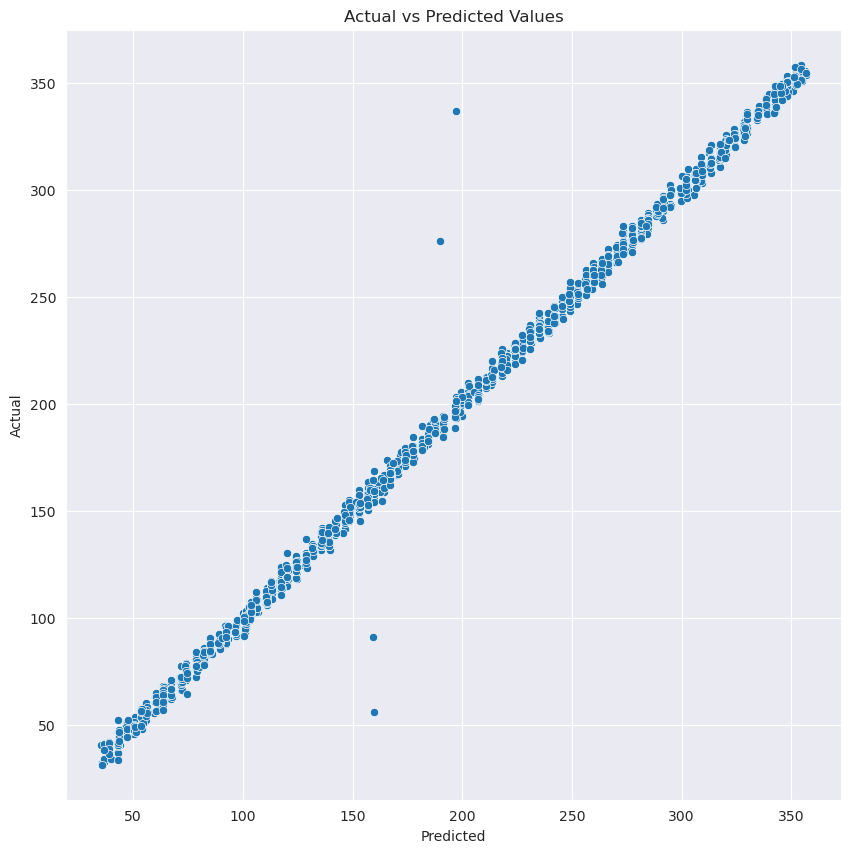

In [49]:
plt.figure(figsize=(10, 10))
sns.scatterplot(x=y_pred, y=y_test)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Actual vs Predicted Values")
plt.show()